In [ ]:
import pandas as pd

df = pd.read_csv("salaries.csv")

# Separate features (inputs) and target
inputs = df.drop('salary_more_then_100k', axis='columns')
target = df['salary_more_then_100k']

df
inputs.head()


  company                  job     degree  salary_more_then_100k
0  google      sales executive  bachelors                      0
1  google      sales executive    masters                      0
2  google     business manager  bachelors                      1
3  google     business manager    masters                      1
4  google  computer programmer  bachelors                      0


,company,job,degree,salary_more_then_100k
0,google,sales executive,bachelors,0
1,google,sales executive,masters,0
2,google,business manager,bachelors,1
3,google,business manager,masters,1
4,google,computer programmer,bachelors,0
5,google,computer programmer,masters,1
6,abc pharma,sales executive,masters,0
7,abc pharma,computer programmer,bachelors,0
8,abc pharma,business manager,bachelors,0
9,abc pharma,business manager,masters,1


**Convert Text Categories to Numbers (Label Encoding)**

Company: google = 2, abc pharma = 0, facebook = 1

Job: business manager = 0, computer programmer = 1, sales executive = 2

Degree: bachelors = 0, masters = 1

In [ ]:
from sklearn.preprocessing import LabelEncoder

# 1. Create a LabelEncoder object for each text column
le_company = LabelEncoder()
le_job = LabelEncoder()
le_degree = LabelEncoder()
le_company

# 2. Transform text to numbers and store as new columns
inputs['company_n'] = le_company.fit_transform(inputs['company'])
inputs['job_n'] = le_job.fit_transform(inputs['job'])
inputs['degree_n'] = le_degree.fit_transform(inputs['degree'])

inputs


,company,job,degree,company_n,job_n,degree_n
0,google,sales executive,bachelors,2,2,0
1,google,sales executive,masters,2,2,1
2,google,business manager,bachelors,2,0,0
3,google,business manager,masters,2,0,1
4,google,computer programmer,bachelors,2,1,0
5,google,computer programmer,masters,2,1,1
6,abc pharma,sales executive,masters,0,2,1
7,abc pharma,computer programmer,bachelors,0,1,0
8,abc pharma,business manager,bachelors,0,0,0
9,abc pharma,business manager,masters,0,0,1


In [7]:
# 3. Drop the old text columns so only numbers remain
inputs_n = inputs.drop(['company', 'job', 'degree'], axis='columns')

inputs_n.head()

,company_n,job_n,degree_n
0,2,2,0
1,2,2,1
2,2,0,0
3,2,0,1
4,2,1,0


In [8]:
from sklearn import tree

# 1. Create Decision Tree model
model = tree.DecisionTreeClassifier()

# 2. Train the model using the numeric features and target
model.fit(inputs_n, target)

# 3. Check training score (accuracy)
print(f"Model Score: {model.score(inputs_n, target) * 100:.0f}%")

Model Score: 100%


**Make Predictions on Custom Profiles**

In [9]:
# Question 1: Is salary of Google, Computer Programmer, with Masters degree > 100k?
# [company=2 (google), job=1 (programmer), degree=1 (masters)]
pred1 = model.predict([[2, 1, 1]])
print("Google Programmer (Masters):", "Salary > 100k" if pred1[0] == 1 else "Salary <= 100k")

# Question 2: Is salary of Google, Computer Programmer, with Bachelors degree > 100k?
# [company=2 (google), job=1 (programmer), degree=0 (bachelors)]
pred2 = model.predict([[2, 1, 0]])
print("Google Programmer (Bachelors):", "Salary > 100k" if pred2[0] == 1 else "Salary <= 100k")

Google Programmer (Masters): Salary > 100k
Google Programmer (Bachelors): Salary <= 100k


c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


**Plot and Visualize the Decision Tree**

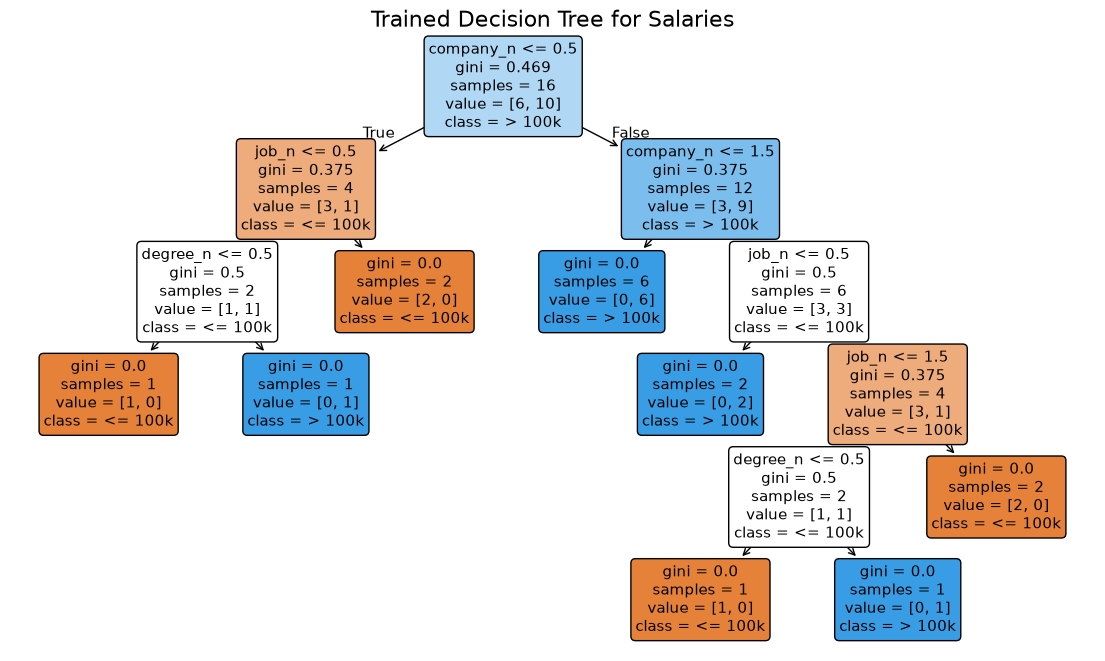

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
tree.plot_tree(
    model,
    feature_names=inputs_n.columns,
    class_names=['<= 100k', '> 100k'],
    filled=True,
    rounded=True
)
plt.title("Trained Decision Tree for Salaries", fontsize=16)
plt.show()

**Create an End-to-End Prediction Function (Using Plain Text!)**

In [11]:
def predict_salary(company_name, job_title, degree_level):
    """
    Takes string inputs, encodes them, and predicts salary range.
    """
    # 1. Transform plain text to the encoded integer
    c = le_company.transform([company_name])[0]
    j = le_job.transform([job_title])[0]
    d = le_degree.transform([degree_level])[0]
    
    # 2. Predict with the model
    prediction = model.predict([[c, j, d]])[0]
    
    result = "> $100k 💰" if prediction == 1 else "<= $100k 📉"
    print(f"Profile: [{company_name} | {job_title} | {degree_level}]")
    print(f"Predicted Salary: {result}\n")
    return prediction

# --- Test with different combinations in plain English! ---
predict_salary('facebook', 'sales executive', 'bachelors')
predict_salary('google', 'sales executive', 'masters')
predict_salary('abc pharma', 'business manager', 'masters')
predict_salary('abc pharma', 'business manager', 'bachelors')

Profile: [facebook | sales executive | bachelors]
Predicted Salary: > $100k 💰

Profile: [google | sales executive | masters]
Predicted Salary: <= $100k 📉

Profile: [abc pharma | business manager | masters]
Predicted Salary: > $100k 💰

Profile: [abc pharma | business manager | bachelors]
Predicted Salary: <= $100k 📉



c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\yzd\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


np.int64(0)

**Save the Model and Encoders**

In [12]:
import joblib

# Bundle the model and encoders together in a dictionary
model_bundle = {
    'model': model,
    'le_company': le_company,
    'le_job': le_job,
    'le_degree': le_degree
}

# Save to disk
joblib.dump(model_bundle, 'salary_decision_tree_bundle.pkl')
print("Model and Encoders saved successfully as 'salary_decision_tree_bundle.pkl'!")

Model and Encoders saved successfully as 'salary_decision_tree_bundle.pkl'!
